# Projet complet — Prédiction de prix synthétiques

**Question :** peut-on réduire l'erreur de prédiction d'un prix simulé en utilisant les caractéristiques du logement plutôt qu'une simple moyenne ? **Pré-requis :** Pandas, split, pipeline et métriques de régression. **Durée :** 2–3 h.

**Contrat de données :** une ligne = un logement artificiel ; surface en m², nombre de chambres, âge en années, distance au centre en km et district. La cible est construite par une équation dans `make_housing_data` avec un bruit aléatoire. Les prix ne représentent aucun marché et ne doivent jamais servir à estimer un logement réel.

**Protocole :** EDA → split → baseline → forêt → MAE/RMSE/R² → analyse d'erreurs. Les transformations sont apprises sur train seulement.

## 1. Décrire la table et ses anomalies

Avant le modèle, vérifiez le nombre de lignes, les types, unités, taux de valeurs manquantes, valeurs impossibles et distribution de la cible. L'âge contient volontairement quelques valeurs manquantes. La présence d'une colonne de district exige un encodage catégoriel ; la forêt ne peut pas consommer directement des chaînes.

Le générateur utilise notamment une contribution positive de la surface et un bruit gaussien. Cette relation est **définie par le code** ; la retrouver sur un graphique ne prouve rien sur la réalité.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from learning_hub.preprocessing import make_housing_data

features, target = make_housing_data(n_samples=600, random_state=42)
data = features.assign(price=target)
print(data.shape); print(data.dtypes); print(data.isna().sum()); print(data.describe(include='all').round(2))
data.head()

## 2. EDA : voir ce que résumera la métrique

L'histogramme montre l'échelle et l'asymétrie éventuelle de la cible. Le nuage surface–prix montre une association marginale : les autres variables et le bruit expliquent la dispersion autour de la tendance. Notez une observation visible et une question que ce graphique ne peut pas résoudre. Une corrélation n'est pas une relation causale.

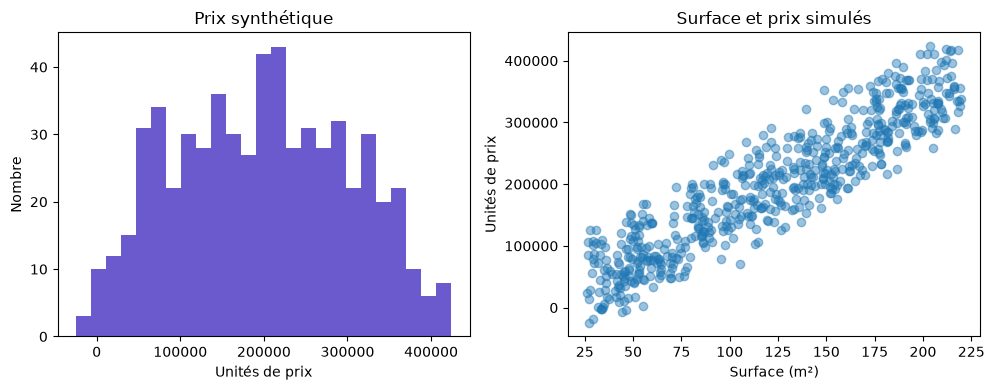

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(data.price, bins=25, color='slateblue')
axes[0].set(title='Prix synthétique', xlabel='Unités de prix', ylabel='Nombre')
axes[1].scatter(data.area_m2, data.price, alpha=0.45)
axes[1].set(title='Surface et prix simulés', xlabel='Surface (m²)', ylabel='Unités de prix')
plt.tight_layout(); plt.show()

## 3. Split et modèles comparables

La baseline `DummyRegressor` prédit la moyenne de `y_train`. Elle fournit le niveau d'erreur d'un modèle qui ignore les caractéristiques. La forêt combine plusieurs arbres, chacun découpant les features par seuils ; elle peut représenter des relations non linéaires.

Chaque candidat contient le même `ColumnTransformer` : médiane pour l'âge manquant, standardisation des variables numériques et `OneHotEncoder` pour le district. Les statistiques et catégories sont apprises pendant `fit(x_train, y_train)` ; le test est seulement transformé et prédit. La MAE est une erreur absolue moyenne en unités de prix simulé ; la RMSE pénalise davantage les grosses erreurs. Un R² négatif signifie qu'un candidat peut être pire qu'une référence constante sur ce split.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from learning_hub.preprocessing import make_tabular_preprocessor

numeric = ['area_m2', 'bedrooms', 'age_years', 'distance_to_center_km']
categorical = ['district']
x_train, x_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)
models = {
    'mean baseline': Pipeline([('prep', make_tabular_preprocessor(numeric, categorical)), ('model', DummyRegressor())]),
    'random forest': Pipeline([('prep', make_tabular_preprocessor(numeric, categorical)), ('model', RandomForestRegressor(n_estimators=60, min_samples_leaf=2, random_state=42, n_jobs=1))]),
}
results = {}
for name, model in models.items():
    model.fit(x_train, y_train)
    prediction = model.predict(x_test)
    results[name] = prediction
    print(name, {'MAE': round(mean_absolute_error(y_test, prediction), 1), 'RMSE': round(mean_squared_error(y_test, prediction) ** 0.5, 1), 'R2': round(r2_score(y_test, prediction), 3)})

### Visualisation explicative — mesurer le gain sur la baseline

Les deux barres utilisent exactement les mêmes observations test. Leur écart est une comparaison descriptive sur ce split. Le ratio d'erreur indique l'ampleur du gain dans ce jeu synthétique ; il ne remplace pas une validation sur d'autres données.

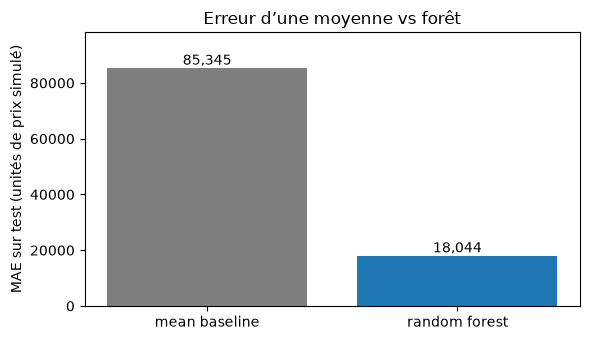

In [ ]:
from sklearn.metrics import mean_absolute_error
mae_by_model = {name: mean_absolute_error(y_test, values) for name, values in results.items()}
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(mae_by_model.keys(), mae_by_model.values(), color=['tab:gray', 'tab:blue'])
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{bar.get_height():,.0f}', ha='center', va='bottom')
ax.set(ylabel='MAE sur test (unités de prix simulé)', title='Erreur d’une moyenne vs forêt')
ax.set_ylim(0, max(mae_by_model.values()) * 1.15)
plt.tight_layout(); plt.show()
print('Ratio forêt/baseline:', round(mae_by_model['random forest'] / mae_by_model['mean baseline'], 3))

## 4. Lire l'amélioration et ses limites

Le graphique des résidus teste si les erreurs ont une structure selon le prix prédit. Les boîtes par district testent si une moyenne globale cache une zone plus difficile. Le nombre d'exemples par district compte : une boîte avec peu de points est instable. Ne réglez pas la forêt à partir de ces résultats test ; pour cela, utilisez une validation interne au train.

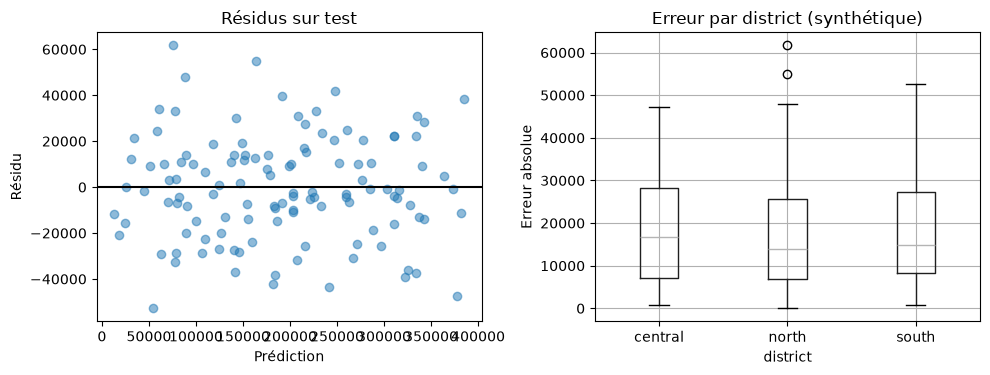

In [ ]:
best_prediction = results['random forest']
residuals = y_test - best_prediction
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(best_prediction, residuals, alpha=0.5); axes[0].axhline(0, color='black')
axes[0].set(xlabel='Prédiction', ylabel='Résidu', title='Résidus sur test')
error_by_district = x_test[['district']].copy()
error_by_district['absolute_error'] = abs(residuals)
error_by_district.boxplot(column='absolute_error', by='district', ax=axes[1])
axes[1].set(title='Erreur par district (synthétique)', ylabel='Erreur absolue'); plt.suptitle(''); plt.tight_layout(); plt.show()
error_by_district.groupby('district').absolute_error.agg(['median', 'mean', 'count']).round(1)

## 5. Conclusion guidée

Rédigez trois phrases : (1) baseline et forêt sur la même métrique et le même split, (2) sous-groupe ou résidu qui mérite une analyse, (3) limite de généralisation. La forêt devrait gagner ici parce que la cible a été fabriquée à partir des features. Cela vérifie le protocole logiciel, pas la validité de la formule pour une ville réelle.

**Expérience suivante :** comparer une régression linéaire en validation croisée, puis seulement après choix évaluer sur test final. Pour de vraies données, vérifier licence, période, définition du prix, doublons de logements, variable temporelle, dépendance géographique et dérive.